# 07 — Semantic Analytics: Ontologi, Taksonomi SKOS, Knowledge Graph, dan Query SPARQL

## (A) Tujuan dan Pemetaan Kerangka Slide Kuliah

**Semantic Analytics** bertujuan menghubungkan data terstruktur dan hasil analitik sebelumnya dengan **konteks, makna domain, taksonomi, dan relasi antar-entitas** agar dapat ditelusuri menggunakan query deklaratif (**SPARQL**) serta penalaran logis (**inferensi RDFS/OWL-RL**).

| Tahap pada Slide Kuliah | Penerapan pada Proyek Bondora P2P Lending | Artefak Utama |
| :--- | :--- | :--- |
| **1. Data** | Dataset bersih `bondora_clean.parquet` (`179.235 × 130`) + sumber data kedua dari hasil analitik Tahap 4 (`p_calibrated` melalui `src/models/inference.py`) dan Tahap 5 (`s3_selected_loans.parquet`, `n = 5.000`) | `data/processed/bondora_clean.parquet`, `data/processed/s3_selected_loans.parquet` |
| **2. Pemrosesan: Ekstraksi Entitas, Relasi, & Konteks** | Identifikasi entitas utama (`bo:Loan`, `bo:Borrower`, `bo:Country`, `bo:RatingClass`, `bo:RiskTier`, `bo:OutcomeGroup`, `bo:Era`, `bo:TenorBand`, `bo:RiskBand`, `bo:Strategy`) beserta relasi urutan pinjaman antar-waktu (`bo:precededBy`) | `src/semantic/sampling.py`, `src/semantic/build_graph.py` |
| **3. Knowledge Representation: Ontologi & Taksonomi** | Skema OWL/RDFS dan taksonomi SKOS (`bo:RatingClass -> skos:broader -> bo:RiskTier`, 4 kelompok hasil `bo:OutcomeGroup`) berformat Turtle dengan label/komentar Bahasa Indonesia (`definisi proyek` eksplisit) | `ontology/bondora_ontology.ttl` |
| **4. Semantic Analytics: Memahami Makna & Hubungan** | 8 query kompetensi SPARQL (`q1.rq` s.d. `q8.rq`), penelusuran jalur properti (`skos:broader`, `bo:precededBy+`), serta penutupan deduktif RDFS/OWL-RL (`owlrl.DeductiveClosure`) untuk kelas terdefinisi (`bo:DefaultedLoan`, `bo:CensoredLoan`, `bo:HighRiskRatedLoan`) | `ontology/queries/q1.rq`..`q8.rq`, `src/semantic/queries.py` |
| **5. Insight & Action** | Reproduksi temuan kunci Tahap 2–5 melalui graf (termasuk reproduksi eksak 100% komposisi portofolio S3) serta temuan relasional baru mengenai rantai peminjaman ulang pasca-default | `reports/tables/07_insight_action.csv`, `reports/figures/07_*.png` |

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import numpy as np
import rdflib
from rdflib import Graph, Namespace
from rdflib.namespace import OWL, RDF, RDFS, SKOS, XSD
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

ONTOLOGY_PATH = PROJECT_ROOT / "ontology" / "bondora_ontology.ttl"
QUERIES_DIR = PROJECT_ROOT / "ontology" / "queries"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
GRAPH_GZ_PATH = PROJECT_ROOT / "data" / "processed" / "bondora_graph.ttl.gz"

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 140)
print("Project root:", PROJECT_ROOT)

Project root: D:\tugas_3_pemodelan_data\bondora-analytics


---
## (B) Ontologi dan Taksonomi (`ontology/bondora_ontology.ttl`)

Ontologi dirancang menggunakan namespace akademik `bo: <http://example.org/bondora#>` dengan memadukan standar **OWL**, **RDFS**, **SKOS**, dan **XSD**:
1. **Kelas Utama (`owl:Class`):** `bo:Loan`, `bo:Borrower`, `bo:Country`, `bo:RatingClass`, `bo:RiskTier` (`rdfs:subClassOf skos:Concept`), `bo:OutcomeGroup` (`rdfs:subClassOf skos:Concept`), `bo:Era`, `bo:TenorBand`, `bo:RiskBand`, `bo:Strategy`.
2. **Kelas Terdefinisi untuk Inferensi (`owl:Class` dengan `owl:equivalentClass` / `rdfs:subClassOf` atas `owl:Restriction`):**
   - `bo:DefaultedLoan`: ekuivalen dengan `bo:Loan` yang memiliki `bo:hasOutcome bo:Default`.
   - `bo:CensoredLoan`: ekuivalen dengan `bo:Loan` yang memiliki `bo:hasOutcome bo:Current` atau `bo:LateNotDefault`.
   - `bo:HighRiskRatedLoan`: ekuivalen dengan `bo:Loan` yang memiliki `bo:ratedAs` ke kelas rating bertingkat risiko tinggi (`bo:Rating_E`, `bo:Rating_F`, `bo:Rating_HR` yang `skos:broader bo:TingkatTinggi`).
3. **Penandaan Eksplisit `"definisi proyek"`:** Pengelompokan tingkat risiko rating (`bo:RiskTier`), era pencatatan (`bo:EraPraPerubahan` $\le$ 2017 vs `bo:EraPascaPerubahan` $\ge$ 2018), pita tenor (`bo:TenorBand`), dan pita risiko model (`bo:RiskBand`) diberi keterangan eksplisit `"definisi proyek"` pada `rdfs:comment`.
4. **Prinsip Etika & Kamus Data:** Atribut sensitif `Gender` dan `Age` **tidak dimasukkan** ke dalam ontologi maupun graf instans; peminjam hanya direpresentasikan oleh ID pseudonim (`bo:Borrower_<UserName>`) dan negara (`bo:borrowerCountry`).

In [2]:
g_ont = Graph()
g_ont.parse(str(ONTOLOGY_PATH), format="turtle")

BO = Namespace("http://example.org/bondora#")
n_classes = len(set(g_ont.subjects(RDF.type, OWL.Class)))
n_obj_props = len(set(g_ont.subjects(RDF.type, OWL.ObjectProperty)))
n_data_props = len(set(g_ont.subjects(RDF.type, OWL.DatatypeProperty)))
n_individuals = len(set(g_ont.subjects(RDF.type, OWL.NamedIndividual)))

print(f"Jumlah triple ontologi : {len(g_ont)}")
print(f"Jumlah kelas OWL       : {n_classes} (10 kelas utama + 3 kelas terdefinisi)")
print(f"Jumlah ObjectProperty  : {n_obj_props}")
print(f"Jumlah DatatypeProperty: {n_data_props}")
print(f"Jumlah individu tetap  : {n_individuals}")

print("\n--- Potongan Turtle: Taksonomi SKOS Rating -> Tingkat Risiko & Kelas Inferensi ---")
ttl_lines = ONTOLOGY_PATH.read_text(encoding="utf-8").splitlines()
print("\n".join(ttl_lines[94:185]))

Jumlah triple ontologi : 321
Jumlah kelas OWL       : 14 (10 kelas utama + 3 kelas terdefinisi)
Jumlah ObjectProperty  : 10
Jumlah DatatypeProperty: 9
Jumlah individu tetap  : 0

--- Potongan Turtle: Taksonomi SKOS Rating -> Tingkat Risiko & Kelas Inferensi ---
    rdfs:label "Pinjaman Berating Tingkat Tinggi"@id ;
    rdfs:comment "Kelas terdefinisi (definisi proyek): pinjaman (bo:Loan) yang memiliki rating (bo:ratedAs) dengan tingkat risiko SKOS bo:TingkatTinggi (E, F, atau HR)."@id ;
    owl:equivalentClass [
        a owl:Restriction ;
        owl:onProperty bo:ratedAs ;
        owl:someValuesFrom [
            a owl:Restriction ;
            owl:onProperty skos:broader ;
            owl:hasValue bo:TingkatTinggi
        ]
    ] .

# =============================================================================
# 3. Properti Objek (Object Properties)
# =============================================================================

bo:hasBorrower a owl:ObjectProperty ;
    rdfs:label 

---
## (C) Sampel Graf dan Statistik Knowledge Graph

Karena batas kinerja pemrosesan in-memory `rdflib`, pembangunan graf instans (`python -m src.semantic.build_graph`) menggunakan strategi sampling tiga lapis yang deterministik (`RANDOM_SEED = 42`):
1. **Sampel Terstratifikasi (`4.000` pinjaman):** Alokasi proporsional berdasarkan strata `Country × OutcomeGroup × Era` dengan minimum `20` pinjaman per strata tidak kosong (strata `< 20` diambil seluruhnya).
2. **Seluruh Portofolio Rekomendasi S3 (`5.000` pinjaman, Tahap 5):** Dimasukkan 100% agar agregasi SPARQL pada portofolio S3 sama persis dengan tabel populasi S3 Tahap 5. Irisan antara sampel stratifikasi dan S3 adalah `106` pinjaman, sehingga gabungan inti mencakup `8.894` pinjaman dari `7.709` peminjam unik.
3. **Perluasan Rantai Peminjam (`11.106` pinjaman tambahan):** Seluruh pinjaman lain milik peminjam pada gabungan inti berjumlah `22.783` pinjaman tambahan (total `31.677` pinjaman, melampaui batas `20.000`). Sesuai aturan kerja Langkah 2.4, perluasan peminjam di luar S3 dikurangi terlebih dahulu dan peminjam S3 dipilih utuh per peminjam dengan `RANDOM_SEED = 42` (`2.869` dari `3.721` peminjam S3 yang memiliki pinjaman tambahan), menghasilkan tepat **`20.000` pinjaman** dan **`340.461` triple** ($\le 600.000$ triple).

> **Catatan Keterbatasan Sampel:** Sampel graf (`20.000` pinjaman) dirancang untuk analisis relasional, validasi taksonomi, dan audit portofolio S3; sampel ini **bukan representatif untuk mengestimasi parameter populasi keseluruhan** (angka populasi tetap mengacu pada tabel Tahap 2–3).

In [3]:
# Muat file graf dan tabel statistik yang sudah terbangun (atau bangun bila belum tersedia)
if not GRAPH_GZ_PATH.exists() or not (TABLES_DIR / "07_graph_stats.csv").exists():
    from src.semantic.build_graph import main as build_graph_main
    build_graph_main()

sample_summary_df = pd.read_csv(TABLES_DIR / "07_sample_summary.csv")
graph_stats_df = pd.read_csv(TABLES_DIR / "07_graph_stats.csv")

print("=== 1. Ringkasan Ukuran Sampel per Sumber, Negara, Hasil, dan Era ===")
display(sample_summary_df[sample_summary_df["kategori"] != "Strata (Country|Outcome|Era)"])

print("\n=== 2. Nilai Antara: Ukuran Sampel per Strata (Country × OutcomeGroup × Era) ===")
display(sample_summary_df[sample_summary_df["kategori"] == "Strata (Country|Outcome|Era)"])

print("\n=== 3. Ringkasan Graf, Waktu Bangun/Muat, dan Jumlah Individu per Kelas ===")
display(graph_stats_df[graph_stats_df["bagian"] != "Triple per Predikat"])

print("\n=== 4. Nilai Antara: Jumlah Triple per Predikat ===")
display(graph_stats_df[graph_stats_df["bagian"] == "Triple per Predikat"])

=== 1. Ringkasan Ukuran Sampel per Sumber, Negara, Hasil, dan Era ===

=== 2. Nilai Antara: Ukuran Sampel per Strata (Country × OutcomeGroup × Era) ===

=== 3. Ringkasan Graf, Waktu Bangun/Muat, dan Jumlah Individu per Kelas ===

=== 4. Nilai Antara: Jumlah Triple per Predikat ===


kategori,subkategori,n_sampel_graf,pct_sampel_graf,n_stratifikasi_4000,pct_stratifikasi_4000,n_populasi,pct_populasi,selisih_proporsi_strat_vs_pop_pp,catatan
Total,Pinjaman unik di graf (final <= 20.000),20000,100.000000,4000,100.00000,179235,100.000000,0.000000,"Perluasan penuh menghasilkan 31,677 pinjaman (> batas 20,000); perluasan peminjam di luar S3 dikurangi (0/2327 peminjam non-S3 dan 2869/3721 peminjam S3 dengan pinjaman tambahan disertakan utuh per peminjam secara acak dengan seed=42) sehingga total = 20,000 pinjaman."
Total,Peminjam unik (UserName),7709,9.060138,3867,4.54476,85087,100.000000,NaN,Rasio terhadap total peminjam unik populasi
Sumber,1. Sampel terstratifikasi (Country x OutcomeGroup x Era),4000,20.000000,4000,100.00000,179235,2.231707,0.000000,Alokasi proporsional dengan minimum 20 per strata tidak kosong
Sumber,2. Portofolio S3 (Tahap 5),5000,25.000000,106,2.65000,5000,2.789634,NaN,Irisan antara sampel stratifikasi dan S3 = 106 pinjaman
Sumber,Gabungan butir 1 U 2 (Inti sebelum perluasan peminjam),8894,44.470000,4000,100.00000,179235,4.962200,NaN,"Peminjam unik pada gabungan inti = 7,709"
Sumber,3. Perluasan peminjam (pinjaman tambahan di luar butir 1 U 2),11106,55.530000,0,0.00000,22783,12.711245,NaN,"Sebelum batas 20.000: total 31,677 pinjaman; setelah hapus perluasan non-S3: 23,096 pinjaman; final: 20,000"
Country,EE,15250,76.250000,2433,60.82500,110714,61.770302,-0.945302,Perbandingan proporsi sampel stratifikasi vs populasi
Country,FI,1941,9.705000,931,23.27500,41955,23.407817,-0.132817,Perbandingan proporsi sampel stratifikasi vs populasi
Country,ES,2767,13.835000,594,14.85000,26270,14.656736,0.193264,Perbandingan proporsi sampel stratifikasi vs populasi
Country,SK,42,0.210000,42,1.05000,296,0.165146,0.884854,Perbandingan proporsi sampel stratifikasi vs populasi


kategori,subkategori,n_sampel_graf,pct_sampel_graf,n_stratifikasi_4000,pct_stratifikasi_4000,n_populasi,pct_populasi,selisih_proporsi_strat_vs_pop_pp,catatan
Strata (Country|Outcome|Era),EE|Berjalan (Current)|EraPascaPerubahan,7467,37.335,939,23.475,42502,23.713002,-0.238002,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Berjalan (Current)|EraPraPerubahan,400,2.000,53,1.325,2609,1.455631,-0.130631,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Default|EraPascaPerubahan,1754,8.770,401,10.025,18336,10.230145,-0.205145,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Default|EraPraPerubahan,423,2.115,278,6.950,12783,7.131978,-0.181978,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Lunas tanpa default|EraPascaPerubahan,2879,14.395,322,8.050,14779,8.245599,-0.195599,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Lunas tanpa default|EraPraPerubahan,1393,6.965,306,7.650,14041,7.833849,-0.183849,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Terlambat belum default|EraPascaPerubahan,887,4.435,114,2.850,5372,2.997182,-0.147182,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Terlambat belum default|EraPraPerubahan,47,0.235,20,0.500,292,0.162915,0.337085,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),ES|Berjalan (Current)|EraPascaPerubahan,395,1.975,36,0.900,1866,1.041091,-0.141091,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),ES|Berjalan (Current)|EraPraPerubahan,21,0.105,20,0.500,40,0.022317,0.477683,Alokasi proporsional (>= 20)


bagian,item,jumlah,persen_dari_total,catatan
Ringkasan,total_triples,340461.000,100.000000,Total triple dalam graf (ontologi + instans)
Ringkasan,ontology_triples,321.000,0.094284,Triple dari ontology/bondora_ontology.ttl
Ringkasan,instance_triples,340140.000,99.905716,Triple instans pinjaman dan peminjam
Ringkasan,reloaded_triples,340461.000,100.000000,Jumlah triple saat dimuat ulang dari bondora_graph.ttl.gz (harus sama persis)
Kinerja & File,waktu_bangun_detik,15.954,NaN,Waktu pembangunan + serialisasi graf (detik)
Kinerja & File,waktu_muat_ulang_detik,13.692,NaN,Waktu muat ulang dari bondora_graph.ttl.gz (detik)
Kinerja & File,ukuran_file_bytes,747538.000,NaN,Ukuran bondora_graph.ttl.gz = 0.713 MB
Individu per Kelas,bo:Loan,20000.000,NaN,Jumlah individu bertipe bo:Loan
Individu per Kelas,bo:Borrower,7709.000,NaN,Jumlah individu bertipe bo:Borrower
Individu per Kelas,bo:Country,4.000,NaN,Jumlah individu bertipe bo:Country


bagian,item,jumlah,persen_dari_total,catatan
Triple per Predikat,rdf:type,27799.0,8.165106,Jumlah triple dengan predikat ini
Triple per Predikat,bo:amount,20000.0,5.874388,Jumlah triple dengan predikat ini
Triple per Predikat,bo:hasBorrower,20000.0,5.874388,Jumlah triple dengan predikat ini
Triple per Predikat,bo:hasOutcome,20000.0,5.874388,Jumlah triple dengan predikat ini
Triple per Predikat,bo:hasTenorBand,20000.0,5.874388,Jumlah triple dengan predikat ini
Triple per Predikat,bo:inEra,20000.0,5.874388,Jumlah triple dengan predikat ini
Triple per Predikat,bo:inRiskBand,20000.0,5.874388,Jumlah triple dengan predikat ini
Triple per Predikat,bo:interestPct,20000.0,5.874388,Jumlah triple dengan predikat ini
Triple per Predikat,bo:isResolved,20000.0,5.874388,Jumlah triple dengan predikat ini
Triple per Predikat,bo:loanDate,20000.0,5.874388,Jumlah triple dengan predikat ini


---
## (D) Delapan Query Kompetensi SPARQL dan Verifikasi Silang `pandas`

Setiap query SPARQL (`ontology/queries/q1.rq` s.d. `q8.rq`) dieksekusi pada graf `rdflib` dan diverifikasi silang secara ketat (`assert` kesamaan eksak / `np.allclose(..., atol=1e-9)`) terhadap perhitungan `pandas` pada sampel yang sama (`data/processed/semantic_sample.parquet`).

In [4]:
if not (TABLES_DIR / "07_query_timings.csv").exists():
    from src.semantic.queries import run_all_queries_and_inference
    run_all_queries_and_inference(save_outputs=True)

timings_df = pd.read_csv(TABLES_DIR / "07_query_timings.csv")
print("=== Ringkasan Waktu Eksekusi & Status Verifikasi Silang 8 Query SPARQL ===")
display(timings_df)

=== Ringkasan Waktu Eksekusi & Status Verifikasi Silang 8 Query SPARQL ===


query_id,file_rq,file_csv,pertanyaan_bisnis,jumlah_baris_hasil,waktu_eksekusi_detik,verifikasi_pandas
Q1,q1.rq,07_q1_rating_tier_country.csv,"Berapa jumlah pinjaman, rata-rata probabilitas gagal bayar 12 bulan terkalibrasi (p_calibrated), dan rata-rata suku bunga tahunan per tingkat risiko rating (SKOS skos:broader) dan negara asal?",11,2.4456,LULUS (assert sama persis)
Q2,q2.rq,07_q2_default12m_country_era.csv,"Berapa jumlah pinjaman teramati 12 bulan, jumlah gagal bayar 12 bulan, dan tingkat gagal bayar 12 bulan (hanya untuk pinjaman yang properti bo:defaultWithin12m-nya tersedia) menurut negara dan era pencatatan?",7,3.4928,LULUS (assert sama persis)
Q3,q3.rq,07_q3_rating_vs_model_mismatch.csv,"Pinjaman mana saja yang memperoleh rating bertingkat risiko rendah (bo:TingkatRendah: AA, A, B) menurut taksonomi rating Bondora, tetapi justru diklasifikasikan ke dalam pita risiko tinggi (bo:PitaRisikoTinggi, p_calibrated >= 0,35) oleh model prediktif LGBM-A (ketidaksepakatan rating vs model)?",10,0.1674,LULUS (assert sama persis)
Q4,q4.rq,07_q4_repeat_borrower_after_default.csv,Peminjam dan pasangan pinjaman mana saja di dalam graf yang menerima pinjaman baru setelah pinjaman sebelumnya langsung tercatat gagal bayar (bo:hasOutcome bo:Default)?,1792,0.3458,LULUS (assert sama persis)
Q5,q5.rq,07_q5_repeat_chain_lengths.csv,"Berapa jumlah pendahulu (ancestor) pada rantai peminjaman ulang (melalui property path bo:precededBy+) untuk setiap pinjaman peminjaman ulang di dalam graf, sehingga dapat dihitung panjang rantai peminjaman ulang (1 + jumlah pendahulu) terpanjang beserta distribusinya per peminjam?",12291,5.0485,LULUS (assert sama persis)
Q6,q6.rq,07_q6_s3_composition_sparql.csv,"Bagaimana komposisi portofolio rekomendasi S3 (bo:selectedBy bo:StrategiS3) menurut negara, tingkat risiko rating (SKOS), kelas rating, dan pita tenor, beserta rata-rata p_calibrated dan tingkat gagal bayar aktual dalam 12 bulan (bo:defaultWithin12m)?",39,1.0996,LULUS (assert sama persis)
Q7,q7.rq,07_q7_high_risk_inferred.csv,"Berapa jumlah pinjaman yang bertipe rdf:type bo:HighRiskRatedLoan menurut negara (dieksekusi pada graf sebelum inferensi vs sesudah inferensi RDFS/OWL-RL, serta dibandingkan dengan penelusuran property path bo:ratedAs/skos:broader* ke bo:TingkatTinggi)?",5,0.4429,LULUS (assert sama persis)
Q8,q8.rq,07_q8_outcome_era_country.csv,Bagaimana perbandingan komposisi 4 kelompok hasil pinjaman (bo:OutcomeGroup) menurut era pencatatan (bo:Era) dan negara asal (bo:Country) di dalam graf?,28,1.8294,LULUS (assert sama persis)


In [5]:
q_files = [
    ("Q1", "q1.rq", "07_q1_rating_tier_country.csv"),
    ("Q2", "q2.rq", "07_q2_default12m_country_era.csv"),
    ("Q3", "q3.rq", "07_q3_rating_vs_model_mismatch.csv"),
    ("Q4", "q4.rq", "07_q4_repeat_borrower_after_default.csv"),
    ("Q5", "q5.rq", "07_q5_chain_distribution.csv"),
    ("Q6", "q6.rq", "07_q6_s3_composition_sparql.csv"),
    ("Q7", "q7.rq", "07_q7_high_risk_inferred.csv"),
    ("Q8", "q8.rq", "07_q8_outcome_era_country.csv"),
]

for qid, rq_name, csv_name in q_files:
    print("=" * 100)
    print(f"[{qid}] File Query: ontology/queries/{rq_name} | Tabel Hasil: reports/tables/{csv_name}")
    print("-" * 100)
    print((QUERIES_DIR / rq_name).read_text(encoding="utf-8").strip())
    df_q = pd.read_csv(TABLES_DIR / csv_name)
    print(f"\nHasil {qid} (total baris = {len(df_q):,}):")
    display(df_q.head(15))
    if qid == "Q5":
        df_q5_raw = pd.read_csv(TABLES_DIR / "07_q5_repeat_chain_lengths.csv")
        print(f"Contoh 10 baris teratas level pinjaman Q5 (07_q5_repeat_chain_lengths.csv, total = {len(df_q5_raw):,} pinjaman lanjutan):")
        display(df_q5_raw.head(10))

[Q1] File Query: ontology/queries/q1.rq | Tabel Hasil: reports/tables/07_q1_rating_tier_country.csv
----------------------------------------------------------------------------------------------------
# Pertanyaan Bisnis Q1:
# Berapa jumlah pinjaman, rata-rata probabilitas gagal bayar 12 bulan terkalibrasi (p_calibrated),
# dan rata-rata suku bunga tahunan per tingkat risiko rating (SKOS skos:broader) dan negara asal?

PREFIX bo: <http://example.org/bondora#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX skos: <http://www.w3.org/2004/02/skos/core#>

SELECT ?country ?riskTier
       (COUNT(?loan) AS ?n_pinjaman)
       (AVG(?p) AS ?p_calibrated_rata2)
       (AVG(?interest) AS ?interest_rata2_pct)
WHERE {
    ?loan rdf:type bo:Loan ;
          bo:originatedIn ?country ;
          bo:ratedAs ?rating ;
          bo:predictedDefaultProb12m ?p ;
          bo:interestPct ?interest .
    ?rating skos:broader ?riskTier .
}
GROUP BY ?country ?riskTier
ORDER BY ?country ?riskT

country,risk_tier,n_pinjaman,p_calibrated_rata2,interest_rata2_pct,pandas_n_pinjaman,pandas_p_calibrated_rata2,pandas_interest_rata2_pct,selisih_maks
EE,TingkatMenengah,7073,0.123904,28.965464,7073,0.123904,28.965464,3.552714e-15
EE,TingkatRendah,4984,0.102440,13.863983,4984,0.102440,13.863983,1.776357e-15
EE,TingkatTidakTersedia,126,0.127984,30.317460,126,0.127984,30.317460,0.000000e+00
EE,TingkatTinggi,3067,0.157544,41.466642,3067,0.157544,41.466642,0.000000e+00
ES,TingkatMenengah,305,0.403325,26.828000,305,0.403325,26.828000,0.000000e+00
ES,TingkatTinggi,2462,0.431591,63.740496,2462,0.431591,63.740496,1.421085e-14
FI,TingkatMenengah,462,0.365680,23.199048,462,0.365680,23.199048,0.000000e+00
FI,TingkatRendah,89,0.280148,14.075618,89,0.280148,14.075618,5.551115e-17
FI,TingkatTinggi,1390,0.385411,44.355806,1390,0.385411,44.355806,0.000000e+00
SK,TingkatMenengah,1,0.234568,35.000000,1,0.234568,35.000000,0.000000e+00


country,era,n_teramati_12m,n_default_12m,default_rate_12m,p_calibrated_rata2,pandas_n_teramati_12m,pandas_n_default_12m,pandas_default_rate_12m,pandas_p_calibrated_rata2,selisih_maks
EE,EraPascaPerubahan,10644,780,0.073281,0.128402,10644,780,0.073281,0.128402,0.000000e+00
EE,EraPraPerubahan,2263,156,0.068935,0.108324,2263,156,0.068935,0.108324,0.000000e+00
ES,EraPascaPerubahan,2350,870,0.370213,0.421658,2350,870,0.370213,0.421658,0.000000e+00
ES,EraPraPerubahan,412,153,0.371359,0.465568,412,153,0.371359,0.465568,0.000000e+00
FI,EraPascaPerubahan,1481,314,0.212019,0.380341,1481,314,0.212019,0.380341,0.000000e+00
FI,EraPraPerubahan,263,74,0.281369,0.330125,263,74,0.281369,0.330125,5.551115e-17
SK,EraPraPerubahan,42,13,0.309524,0.442954,42,13,0.309524,0.442954,5.551115e-17


loan_number,country,rating,era,outcome_code,amount,interest_pct,p_calibrated,default_12m
675424,FI,B,EraPraPerubahan,Default,1959.0,16.10,0.535852,1
710436,FI,B,EraPraPerubahan,Default,3185.0,15.29,0.457746,0
660500,FI,B,EraPraPerubahan,Default,5852.0,14.48,0.447013,1
668655,FI,B,EraPraPerubahan,RepaidNoDefault,6601.0,13.67,0.404145,0
754592,FI,A,EraPascaPerubahan,Default,1965.0,12.18,0.404145,1
260959,FI,B,EraPraPerubahan,Current,1300.0,31.00,0.357276,0
696047,FI,B,EraPraPerubahan,Current,1393.0,13.01,0.357276,0
1039029,EE,B,EraPascaPerubahan,Default,530.0,13.99,0.357276,1
1104377,EE,B,EraPascaPerubahan,Current,530.0,16.58,0.357276,0
1637079,EE,A,EraPascaPerubahan,Current,9782.0,9.53,0.357276,0


borrower_uri_id,country,prev_loan_number,prev_loan_date,next_loan_number,next_loan_date,next_outcome_code,next_p_calibrated
Borrower_element,EE,45,2009-03-07,1104622,2019-05-29,Current,0.030501
Borrower_kurasawa,EE,1424,2009-12-06,1517,2009-12-10,Default,0.447013
Borrower_kurasawa,EE,1439,2009-12-04,1424,2009-12-06,Default,0.293930
Borrower_kurasawa,EE,1465,2009-12-03,1439,2009-12-04,Default,0.285714
Borrower_kurasawa,EE,1517,2009-12-10,1430625,2019-09-07,Default,0.068891
Borrower_mariom,EE,2663,2010-03-23,2747,2010-03-30,Default,0.325221
Borrower_Miizu,EE,2707,2010-03-29,3028,2010-04-18,Default,0.293930
Borrower_mariom,EE,2747,2010-03-30,1510004,2019-10-01,RepaidNoDefault,0.102776
Borrower_Vladislav,EE,2849,2010-04-01,2863,2010-04-02,Default,0.293930
Borrower_Vladislav,EE,2863,2010-04-02,3608,2010-06-02,Default,0.325221


panjang_rantai_peminjam,jumlah_peminjam_sparql,jumlah_peminjam_pandas,persen_peminjam,jumlah_pinjaman_dalam_rantai
1,4496,4496,58.321442,4496
2,916,916,11.882216,1832
3,695,695,9.015437,2085
4,478,478,6.200545,1912
5,250,250,3.242963,1250
6,212,212,2.750032,1272
7,126,126,1.634453,882
8,105,105,1.362044,840
9,83,83,1.076664,747
10,75,75,0.972889,750


loan_number,borrower_uri_id,country,n_pendahulu,panjang_rantai_pada_pinjaman
2293829,Borrower_BO349551,EE,26,27
2260330,Borrower_BO349551,EE,25,26
2155598,Borrower_BO3K516A,EE,24,25
2199267,Borrower_BO349551,EE,24,25
1987892,Borrower_BOKAA242,EE,23,24
2086494,Borrower_BO3K516A,EE,23,24
2102036,Borrower_BO349551,EE,23,24
2251095,Borrower_raitroland,EE,23,24
2287098,Borrower_BO49AK77,EE,23,24
1301730,Borrower_BO7256A4A,ES,22,23


country,risk_tier,rating,tenor_band,n_pinjaman,p_calibrated_rata2,n_default_12m,default_rate_12m,pandas_n_pinjaman,pandas_p_calibrated_rata2,pandas_n_default_12m,pandas_default_rate_12m,selisih_maks
EE,TingkatMenengah,C,Tenor_13_24,20,0.030776,1,0.050000,20,0.030776,1,0.050000,3.469447e-18
EE,TingkatMenengah,C,Tenor_25_36,100,0.043345,2,0.020000,100,0.043345,2,0.020000,6.938894e-18
EE,TingkatMenengah,C,Tenor_37_59,15,0.050924,0,0.000000,15,0.050924,0,0.000000,0.000000e+00
EE,TingkatMenengah,C,Tenor_60,112,0.045786,1,0.008929,112,0.045786,1,0.008929,0.000000e+00
EE,TingkatMenengah,D,Tenor_13_24,228,0.065035,10,0.043860,228,0.065035,10,0.043860,0.000000e+00
EE,TingkatMenengah,D,Tenor_25_36,649,0.089502,66,0.101695,649,0.089502,66,0.101695,0.000000e+00
EE,TingkatMenengah,D,Tenor_37_59,95,0.097123,6,0.063158,95,0.097123,6,0.063158,1.387779e-17
EE,TingkatMenengah,D,Tenor_60,683,0.088650,68,0.099561,683,0.088650,68,0.099561,0.000000e+00
EE,TingkatRendah,B,Tenor_60,2,0.000000,0,0.000000,2,0.000000,0,0.000000,0.000000e+00
EE,TingkatTinggi,E,Tenor_25_36,130,0.126903,14,0.107692,130,0.126903,14,0.107692,2.775558e-17


country,tanpa_inferensi,dengan_inferensi_owlrl,jalur_property_path,hitung_pandas,selisih
EE,0,3067,3067,3067,0
ES,0,2462,2462,2462,0
FI,0,1390,1390,1390,0
SK,0,41,41,41,0
TOTAL,0,6960,6960,6960,0


era,country,outcome_code,n_pinjaman,p_calibrated_rata2,proporsi_dlm_era_negara,pandas_n_pinjaman,pandas_p_calibrated_rata2,pandas_proporsi_dlm_era_negara,selisih_maks
EraPascaPerubahan,EE,Current,7467,0.120510,0.574960,7467,0.120510,0.574960,0.000000e+00
EraPascaPerubahan,EE,Default,1754,0.157698,0.135058,1754,0.157698,0.135058,2.775558e-17
EraPascaPerubahan,EE,LateNotDefault,887,0.143147,0.068299,887,0.143147,0.068299,0.000000e+00
EraPascaPerubahan,EE,RepaidNoDefault,2879,0.117294,0.221683,2879,0.117294,0.221683,0.000000e+00
EraPascaPerubahan,ES,Current,395,0.399900,0.167728,395,0.399900,0.167728,0.000000e+00
EraPascaPerubahan,ES,Default,1335,0.432068,0.566879,1335,0.432068,0.566879,5.551115e-17
EraPascaPerubahan,ES,LateNotDefault,88,0.397756,0.037367,88,0.397756,0.037367,0.000000e+00
EraPascaPerubahan,ES,RepaidNoDefault,537,0.417138,0.228025,537,0.417138,0.228025,0.000000e+00
EraPascaPerubahan,FI,Current,538,0.363112,0.320620,538,0.363112,0.320620,0.000000e+00
EraPascaPerubahan,FI,Default,583,0.414006,0.347437,583,0.414006,0.347437,0.000000e+00


---
## (E) Inferensi RDFS / OWL-RL (`owlrl.DeductiveClosure`)

Penutupan deduktif RDFS/OWL-RL dijalankan pada **salinan graf** (tanpa menimpa berkas graf asli) menggunakan `owlrl.DeductiveClosure`. Inferensi secara otomatis mengklasifikasikan individu `bo:Loan` ke dalam tiga kelas terdefinisi:
1. `bo:DefaultedLoan`: pinjaman dengan `bo:hasOutcome bo:Default` (`4.460` individu).
2. `bo:CensoredLoan`: pinjaman dengan `bo:hasOutcome bo:Current` atau `bo:LateNotDefault` (`10.024` individu).
3. `bo:HighRiskRatedLoan`: pinjaman dengan `bo:ratedAs` kelas rating yang memiliki `skos:broader bo:TingkatTinggi` (`6.960` individu).

Ketiga hasil inferensi diverifikasi menghasilkan jumlah yang **identik 100%** dengan penelusuran SPARQL manual maupun hitungan langsung `pandas`.

In [6]:
inf_df = pd.read_csv(TABLES_DIR / "07_inference_summary.csv")
print("=== Ringkasan Inferensi RDFS/OWL-RL (reports/tables/07_inference_summary.csv) ===")
display(inf_df)

=== Ringkasan Inferensi RDFS/OWL-RL (reports/tables/07_inference_summary.csv) ===


metrik_atau_kelas,sebelum_inferensi,sesudah_inferensi_owlrl,selisih_atau_manual_sparql,hitung_pandas,waktu_detik,status_verifikasi,catatan
total_triples,340461,438342,97881,NaN,48.4942,LULUS,Penutupan deduktif RDFS/OWL-RL pada salinan graf (graf asli tidak ditimpa)
bo:DefaultedLoan,0,4460,4460,4460.0,48.4942,LULUS (identik),Pinjaman dengan bo:hasOutcome bo:Default
bo:CensoredLoan,0,10024,10024,10024.0,48.4942,LULUS (identik),Pinjaman dengan bo:hasOutcome bo:Current atau bo:LateNotDefault
bo:HighRiskRatedLoan,0,6960,6960,6960.0,48.4942,LULUS (identik),"Pinjaman dengan bo:ratedAs rating yang skos:broader bo:TingkatTinggi (E, F, HR)"


---
## (F) Insight & Action: Reproduksi Temuan Sebelumnya dan Wawasan Relasional Baru

Tabel `reports/tables/07_insight_action.csv` memetakan bagaimana query SPARQL pada *knowledge graph*:
1. **Mereproduksi pola arah temuan Tahap 2–4** (urutan risiko negara `EE < FI < ES < SK` pada Q2 dan urutan risiko menurut tingkat rating SKOS serta deteksi ketidaksepakatan rating rendah vs risiko model tinggi pada Q1/Q3), dengan catatan tegas bahwa angka pada Q1–Q3 adalah **angka sampel**.
2. **Mereproduksi secara eksak 100% komposisi portofolio rekomendasi S3 Tahap 5** melalui Q6 (`EE 70,00%`, `ES 21,62%`, `FI 8,38%`; `F+HR 22,94%`; `Tenor 60 bulan 59,20%`; rata-rata `p_calibrated` `17,91%`; realisasi default 12 bulan aktual `19,24%`) karena seluruh `5.000` pinjaman S3 dimuat penuh di dalam graf.
3. **Menghasilkan wawasan relasional baru (Q4 & Q5)** melalui relasi urutan `bo:precededBy` antar-pinjaman milik peminjam yang sama yang tidak terlihat pada analisis tabel per-baris di Tahap 1–5.

In [7]:
insight_df = pd.read_csv(TABLES_DIR / "07_insight_action.csv")
for idx, row in insight_df.iterrows():
    print(f"[{idx+1}] Temuan       : {row['temuan_sebelumnya']}")
    print(f"    Sumber Tahap : {row['sumber_tahap']}")
    print(f"    Query SPARQL : {row['query_sparql']}")
    print(f"    Hasil Graf   : {row['hasil_graf']}")
    print(f"    Hasil Acuan  : {row['hasil_populasi']}")
    print(f"    Catatan      : {row['catatan']}\n")
display(insight_df)

[1] Temuan       : Perbedaan tingkat gagal bayar antar negara dan pergeseran komposisi hasil menurut era pencatatan
    Sumber Tahap : Tahap 2 (EDA) & Tahap 3 (Diagnostic: H1, H7)
    Query SPARQL : Q2 (07_q2_default12m_country_era.csv) & Q8 (07_q8_outcome_era_country.csv)
    Hasil Graf   : Default rate 12 bulan pada sampel graf (n=17,455 teramati): EE=7.25% (n=12,907), ES=37.04% (n=2,762), FI=22.25% (n=1,744), SK=30.95% (n=42). Urutan risiko negara (EE < FI < ES < SK) konsisten dengan populasi.
    Hasil Acuan  : Populasi default_12m teramati (Tahap 2-3, n=148.369): EE 15,28%, FI 24,25%, ES 40,26%, SK 47,26% (selisih ES-EE = +24,98 poin persentase).
    Catatan      : ANGKA SAMPEL: Proporsi sampel dipengaruhi masuknya seluruh 5.000 pinjaman S3 (2021-2022) dan perluasan peminjam; gunakan angka Tahap 2-3 untuk estimasi populasi.

[2] Temuan       : Urutan tingkat gagal bayar monoton terhadap kelas rating (AA s.d. HR) namun terdapat deviasi prediktif tingkat individu
    Sumber Tahap : 

temuan_sebelumnya,sumber_tahap,query_sparql,hasil_graf,hasil_populasi,catatan
Perbedaan tingkat gagal bayar antar negara dan pergeseran komposisi hasil menurut era pencatatan,"Tahap 2 (EDA) & Tahap 3 (Diagnostic: H1, H7)",Q2 (07_q2_default12m_country_era.csv) & Q8 (07_q8_outcome_era_country.csv),"Default rate 12 bulan pada sampel graf (n=17,455 teramati): EE=7.25% (n=12,907), ES=37.04% (n=2,762), FI=22.25% (n=1,744), SK=30.95% (n=42). Urutan risiko negara (EE < FI < ES < SK) konsisten dengan populasi.","Populasi default_12m teramati (Tahap 2-3, n=148.369): EE 15,28%, FI 24,25%, ES 40,26%, SK 47,26% (selisih ES-EE = +24,98 poin persentase).",ANGKA SAMPEL: Proporsi sampel dipengaruhi masuknya seluruh 5.000 pinjaman S3 (2021-2022) dan perluasan peminjam; gunakan angka Tahap 2-3 untuk estimasi populasi.
Urutan tingkat gagal bayar monoton terhadap kelas rating (AA s.d. HR) namun terdapat deviasi prediktif tingkat individu,Tahap 3 (Diagnostic: H2) & Tahap 4 (Predictive: LGBM-A),Q1 (07_q1_rating_tier_country.csv) & Q3 (07_q3_rating_vs_model_mismatch.csv),"Rata-rata p_calibrated sampel menurut tingkat risiko SKOS: TingkatRendah=10.56% (n=5,073), TingkatMenengah=14.90% (n=7,841), TingkatTinggi=30.17% (n=6,960); ditemukan 10 pinjaman TingkatRendah (AA/A/B) yang masuk PitaRisikoTinggi (p >= 0,35) di Q3.","Populasi Tahap 3 menunjukkan default rate 12m naik monoton dari AA (3,82%) hingga HR (52,70%); model LGBM-A (ROC-AUC uji 0,7152) menangkap sinyal arus kas dan beban kewajiban di luar huruf rating.",ANGKA SAMPEL: Menunjukkan manfaat menggabungkan taksonomi SKOS (bo:RiskTier) dengan skor model (bo:inRiskBand) untuk menyaring anomali rating rendah berisiko model tinggi.
"Komposisi dan kinerja portofolio optimasi berbatas S3 (n=5.000 pinjaman, anggaran EUR 250.000)",Tahap 5 (Prescriptive: 06_strategy_results.csv & 06_s3_composition.csv),Q6 (07_q6_s3_composition_sparql.csv),"n=5,000 pinjaman S3: EE 70.00%, ES 21.62%, FI 8.38%; F+HR 22.94%; Tenor 60 bln 59.20%; rata-rata p_calibrated 17.91%; realisasi default 12m aktual 19.24%.","Populasi S3 Tahap 5 (n=5.000, anggaran EUR 250.000): EE 70,00%, ES 21,62%, FI 8,38%; F+HR 22,94%; Tenor 60 bulan 59,20%; rata-rata p_calibrated 17,91%; realisasi default 12m aktual 19,24%.",ANGKA LENGKAP (IDENTIK 100%): Seluruh 5.000 pinjaman S3 dimasukkan penuh ke dalam graf sehingga agregasi SPARQL Q6 mereproduksi angka Tahap 5 secara eksak.
Temuan relasional baru (belum ada di Tahap 1-5): peminjam yang memperoleh pinjaman baru setelah pinjaman sebelumnya berstatus akhir Default,Tahap 6 (Semantic Analytics — relasi bo:precededBy),Q4 (07_q4_repeat_borrower_after_default.csv),"Tercatat 1,792 pasangan transisi pinjaman (milik 837 peminjam unik di graf) di mana pinjaman baru memiliki pendahulu langsung berstatus akhir bo:Default; 1,685 (94.03%) dari pinjaman lanjutan tersebut juga berakhir Default, dan 818 di antaranya terpilih dalam portofolio S3.",Tidak dihitung pada model tabular per-baris Tahap 1-5 karena relasi antar-pinjaman milik peminjam yang sama tidak direpresentasikan sebagai graf urutan.,"WAWASAN RELASIONAL SAMPEL (PERTANYAAN TINDAK LANJUT): Karena bo:Default mencerminkan status akhir pinjaman (sebagian pinjaman lanjutan dicairkan ketika pinjaman lama masih berjalan sebelum akhirnya gagal bayar bersama-sama), apakah kebijakan seleksi investor perlu membatasi pinjaman beruntun dari peminjam yang memiliki eksposur pinjaman sebelumnya?"
Temuan relasional baru (belum ada di Tahap 1-5): struktur panjang rantai peminjaman ulang per peminjam,Tahap 6 (Semantic Analytics — property path bo:precededBy+),Q5 (07_q5_repeat_chain_lengths.csv & 07_q5_chain_distribution.csv),"Dari 7,709 peminjam di graf, 3,213 peminjam memiliki >= 2 pinjaman (total 12,291 pinjaman lanjutan), 1,124 peminjam memiliki rantai >= 5 pinjaman, dan panjang rantai maksimum tercatat 27 pinjaman berurutan.","Tahap 5 hanya membatasi bobot negara, F+HR, dan tenor 60 bulan tanpa batas konsentrasi jumlah pinjaman per peminjam (UserName).",WAWASAN RELASIO

---
## (G) Visualisasi Semantik (`reports/figures/07_*.png` & `reports/07_kg_interactive.html`)

Empat grafik statis wajib (dan satu visualisasi jaringan interaktif `pyvis`):
1. `07_ontology_schema.png`: Diagram skema kelas utama, kelas inferensi OWL-RL, properti objek, dan properti data.
2. `07_kg_example_subgraph.png`: Subgraf nyata peminjam **`bo:Borrower_BO1113924`** (negara `ES`) yang memiliki **3 pinjaman berurutan** (`LoanNumber`: **`1571624` $\leftarrow$ `1752900` $\leftarrow$ `1933569`** melalui `bo:precededBy`), ketiganya berstatus akhir `bo:Default`, dengan pinjaman ketiga (`bo:Loan_1933569`) terpilih dalam portofolio `bo:StrategiS3`.
3. `07_taxonomy_rating_risk.png`: Pohon taksonomi SKOS `bo:RatingClass -> skos:broader -> bo:RiskTier` beserta 4 konsep `bo:OutcomeGroup`, 3 `bo:RiskBand`, dan 2 `bo:Era`.
4. `07_triples_by_predicate.png`: Distribusi jumlah triple menurut predikat RDF/OWL/SKOS/RDFS (`total = 340.461` triple).
5. `reports/07_kg_interactive.html`: Visualisasi graf interaktif berbasis `pyvis` (`0,695 MB` $< 5	ext{ MB}$).

=== 07_ontology_schema.png ===
=== 07_kg_example_subgraph.png ===
=== 07_taxonomy_rating_risk.png ===
=== 07_triples_by_predicate.png ===


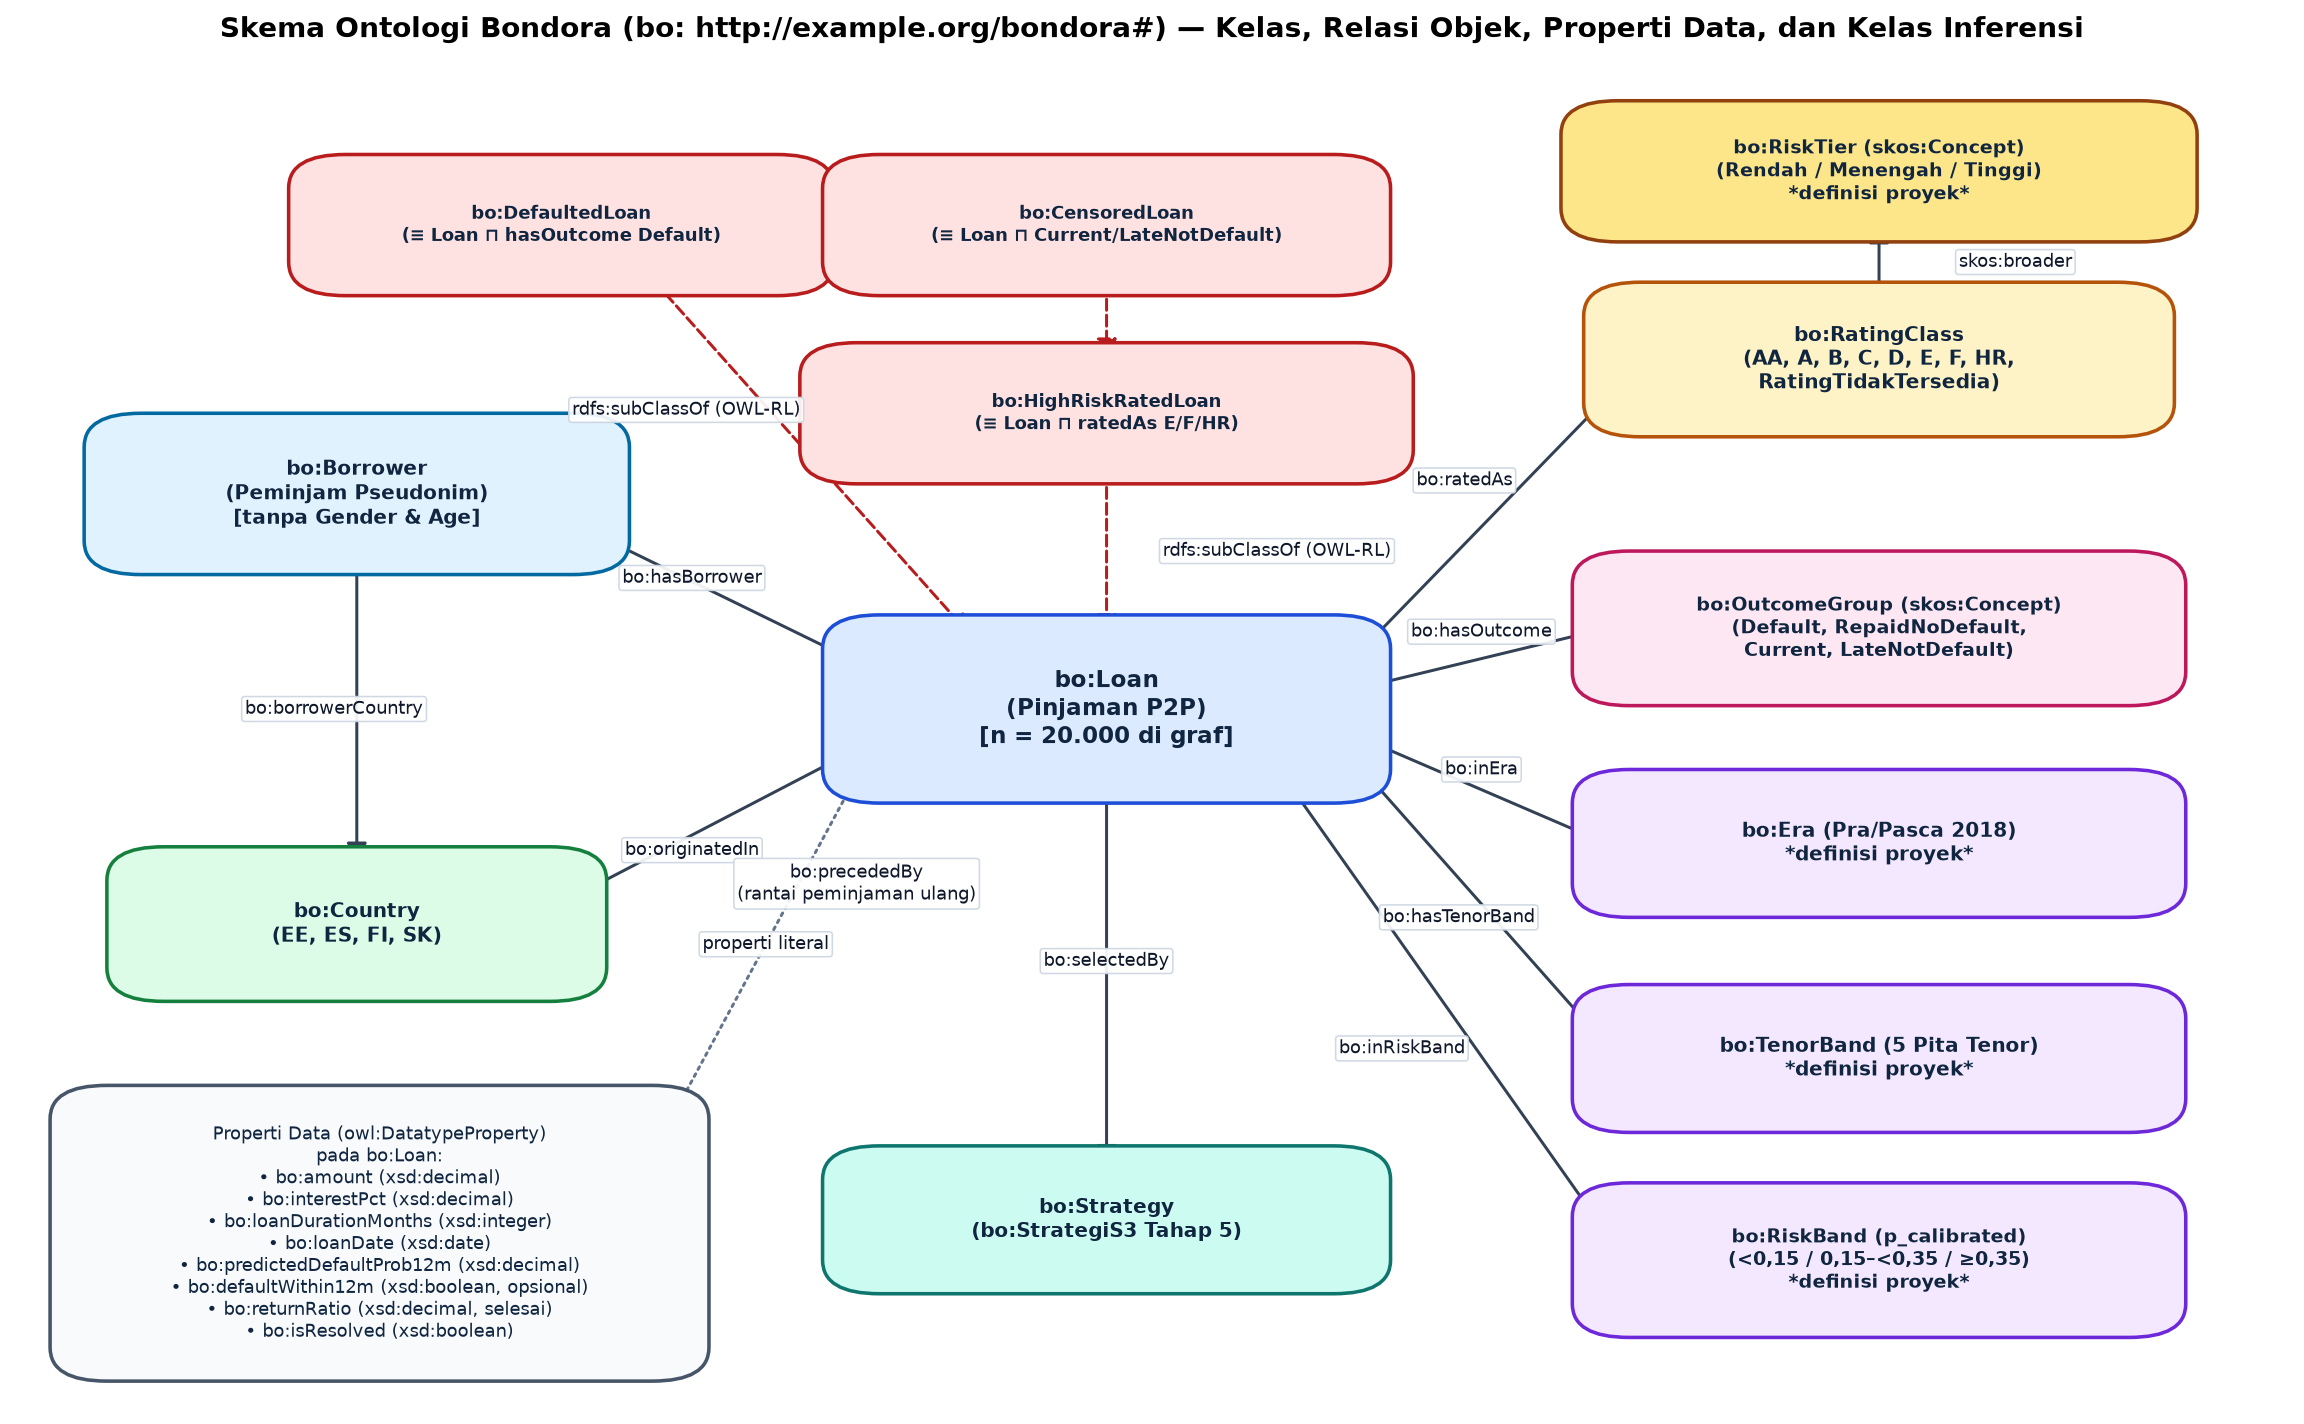

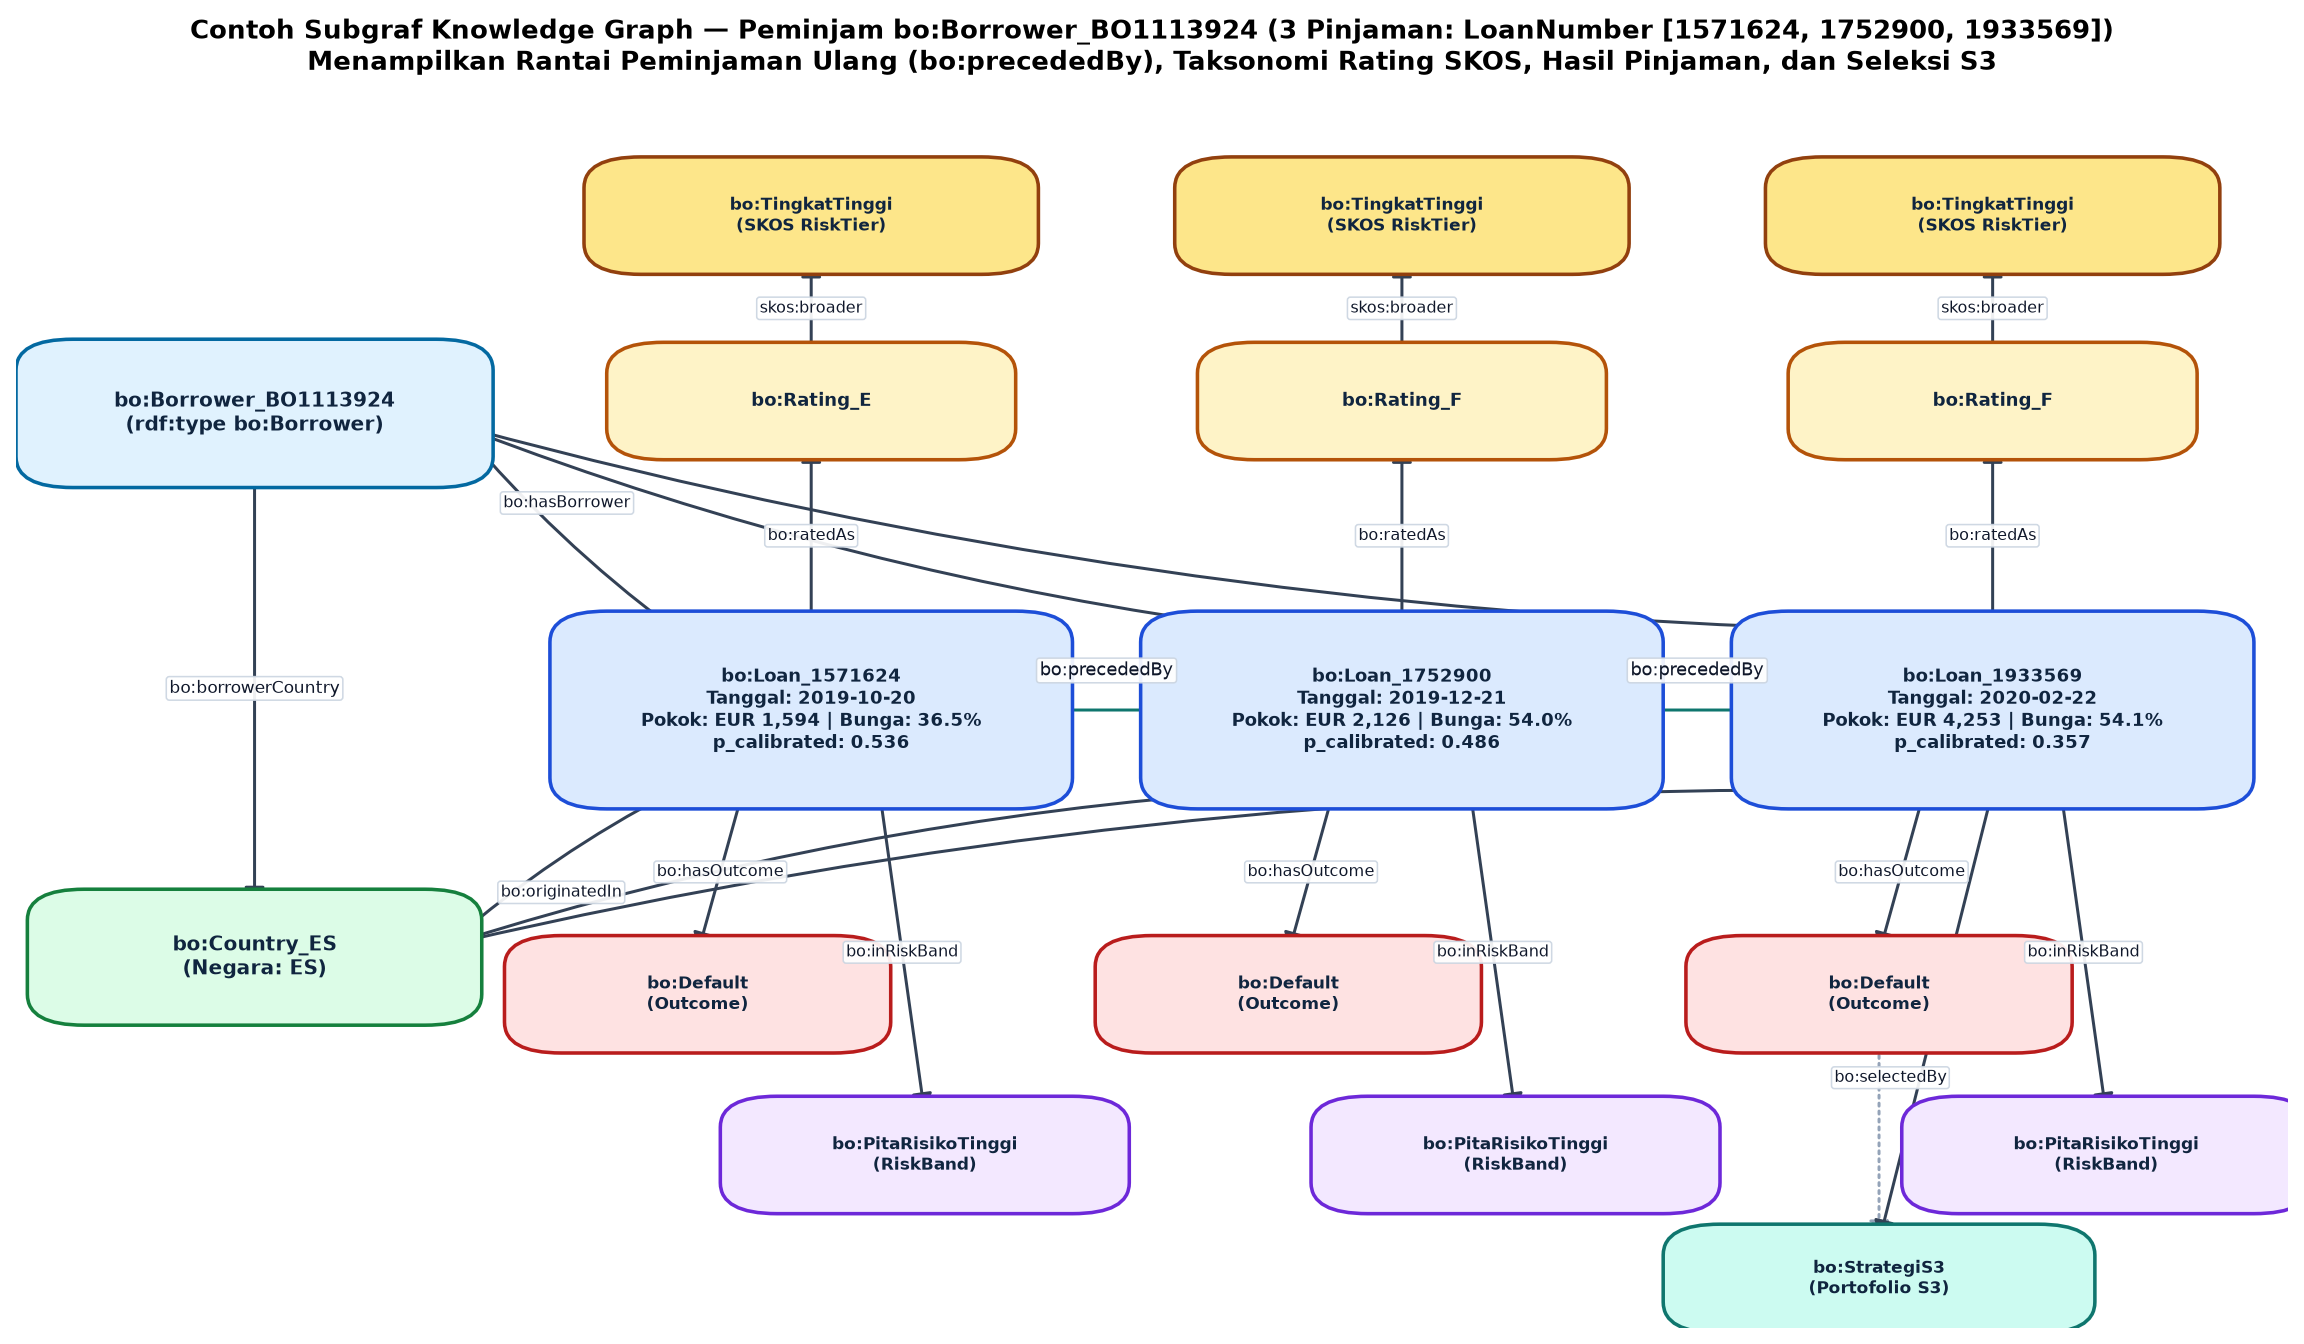

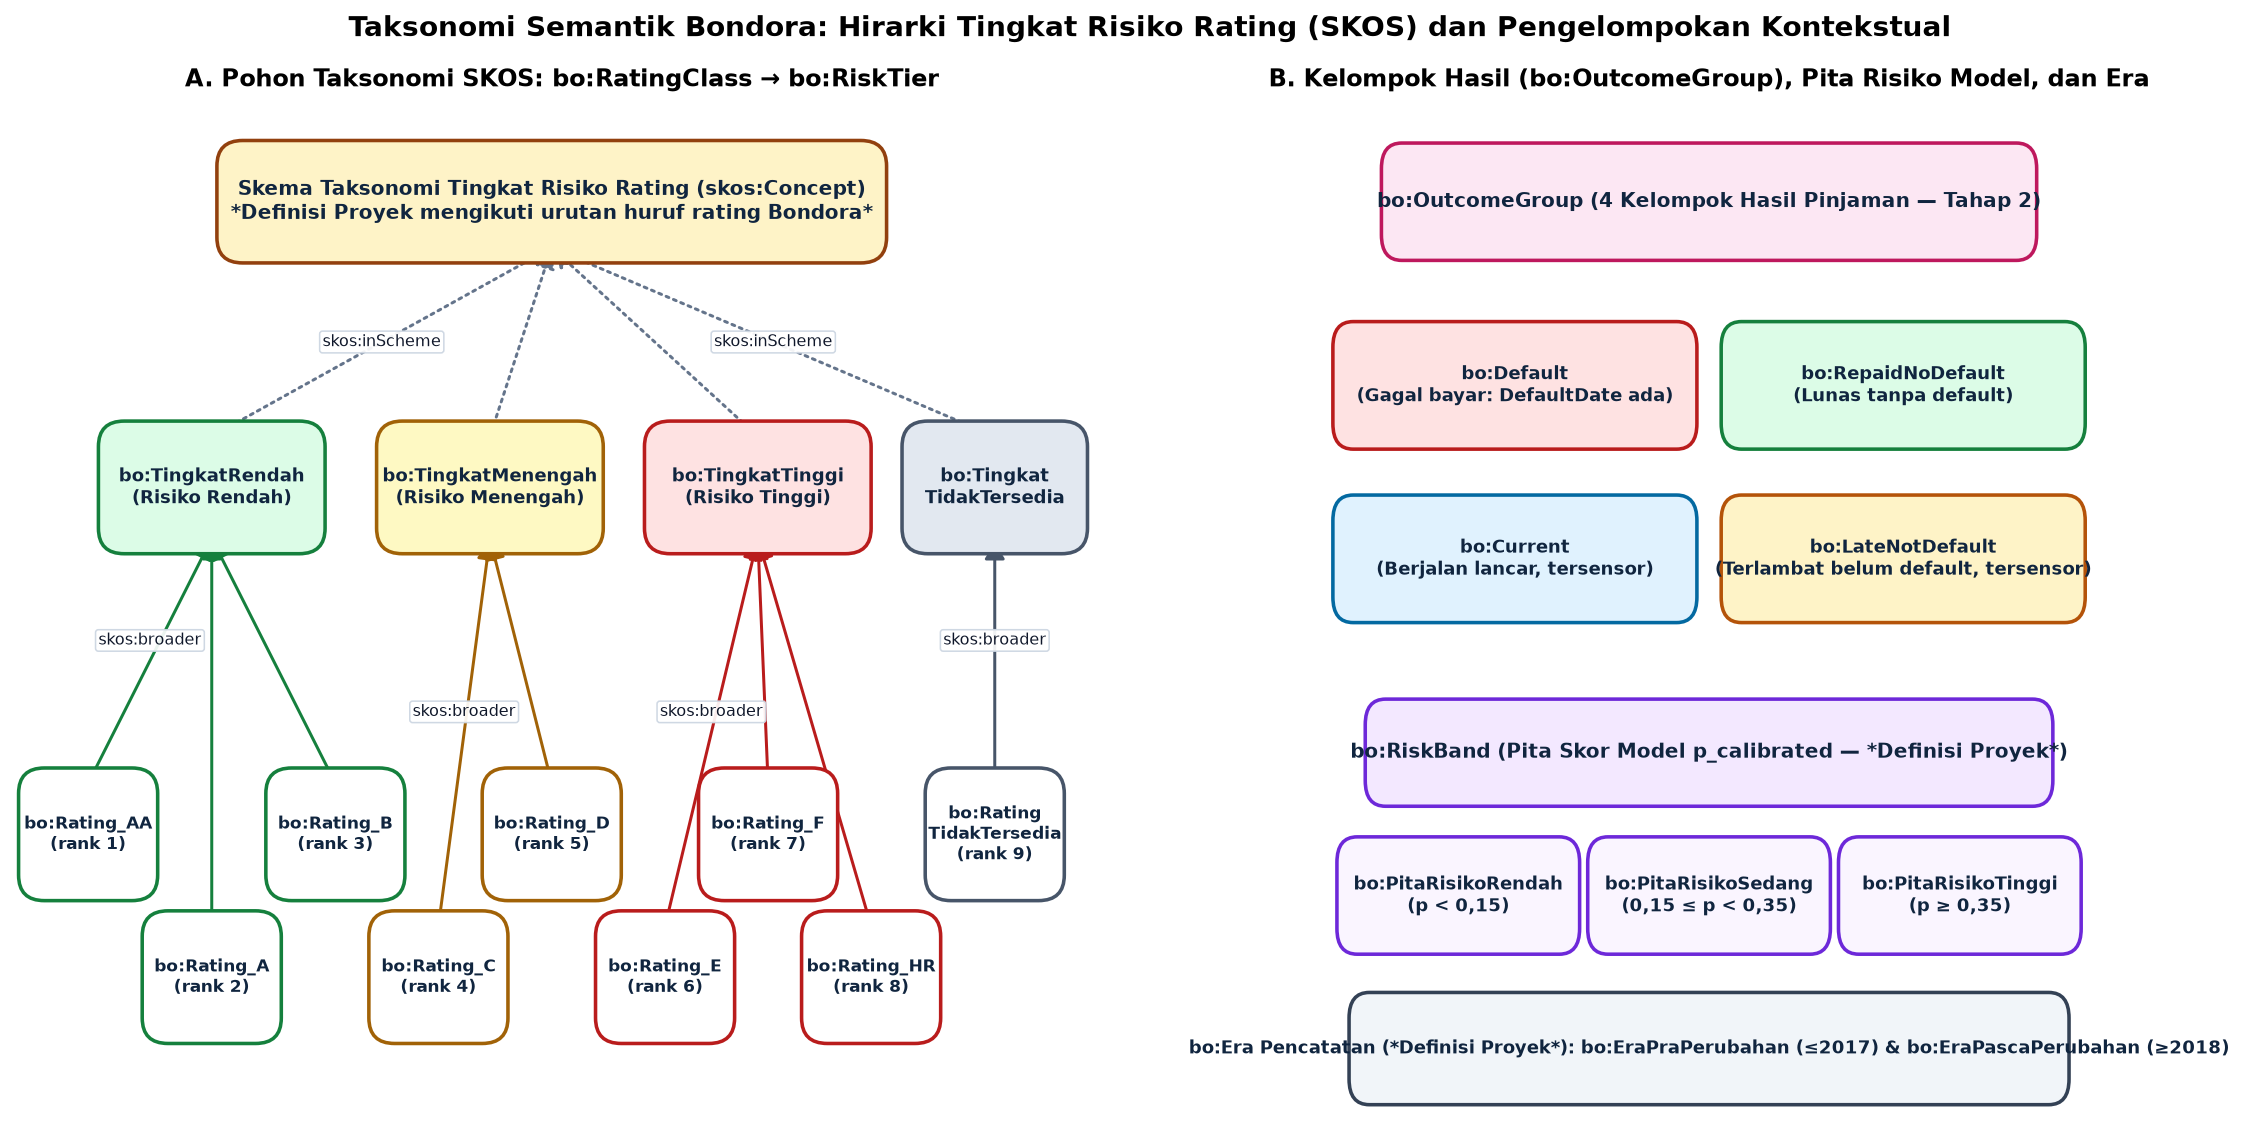

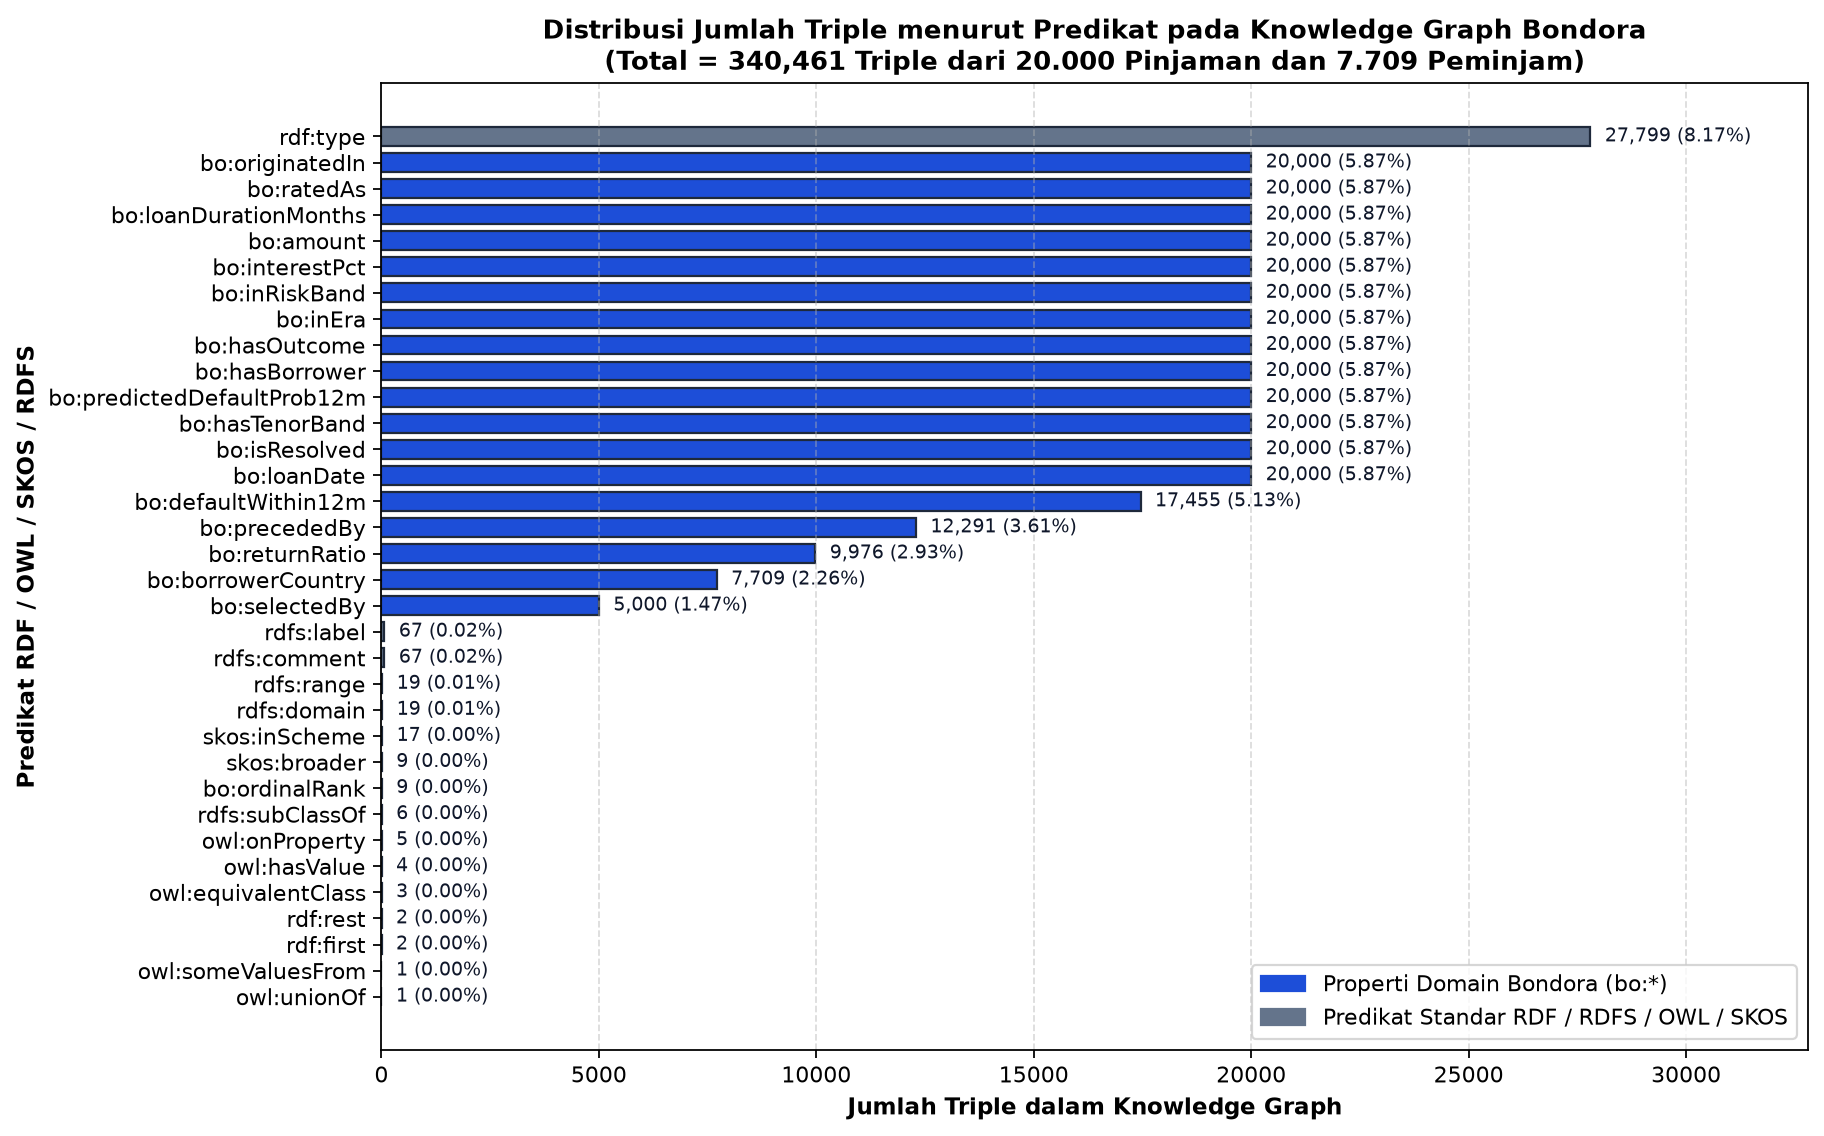

In [8]:
for fig_name in [
    "07_ontology_schema.png",
    "07_kg_example_subgraph.png",
    "07_taxonomy_rating_risk.png",
    "07_triples_by_predicate.png",
]:
    fig_path = FIGURES_DIR / fig_name
    print(f"=== {fig_name} ===")
    display(Image(filename=str(fig_path)))

---
## (H) Keterbatasan dan Pertimbangan Etika

1. **Data Terstruktur Tanpa Teks Bebas:** Kerangka konseptual *Semantic Analytics* di perkuliahan mencakup ekstraksi entitas/relasi dari gabungan data terstruktur dan tidak terstruktur (*unstructured text*). Dataset publik Bondora hampir seluruhnya bersifat terstruktur tabular tanpa deskripsi narasi pengajuan pinjaman, sehingga pemrosesan semantik difokuskan pada pemodelan skema ontologi, taksonomi SKOS, integrasi skor prediktif/preskriptif, dan ekstraksi relasi sekuensial antar-pinjaman (`bo:precededBy`).
2. **Representativitas Sampel Graf (`20.000` dari `179.235` Pinjaman):** Untuk menjaga waktu eksekusi SPARQL dan inferensi in-memory `rdflib` tetap berada di bawah ambang 60 detik per query, graf instans dibatasi pada `20.000` pinjaman (`4.000` sampel stratifikasi + `5.000` portofolio S3 + `11.106` perluasan peminjam). Masuknya seluruh pinjaman S3 dan perluasan peminjam membuat distribusi sampel bergeser terhadap populasi (mis. porsi `EE` di graf `76,25%` vs populasi `61,77%`, sedangkan pada sub-sampel stratifikasi murni `4.000` pinjaman porsinya `60,82%`). Oleh sebab itu, agregasi sampel graf tidak boleh dibaca sebagai parameter populasi.
3. **Ketiadaan Waktu Transisi Status Real-Time pada Rantai Peminjaman Ulang:** Properti `bo:hasOutcome bo:Default` merepresentasikan status hasil akhir pinjaman pada tanggal laporan (`2021-07-20`). Pada pasangan pinjaman `bo:precededBy` di Q4, sebagian pinjaman berikutnya dicairkan ketika pinjaman pendahulunya masih berstatus berjalan sebelum akhirnya kedua pinjaman tersebut gagal bayar. Temuan Q4 harus diinterpretasikan sebagai asosiasi sekuensial pada riwayat peminjam, bukan klaim sebab-akibat.
4. **Etika dan Privasi Data (`Gender`, `Age`, dan Kode Tanpa Kamus):** Konsisten dengan temuan *fairness* Tahap 3, atribut demografis `Gender` dan `Age` sengaja **tidak dimasukkan** ke dalam ontologi maupun *knowledge graph*. Peminjam hanya diwakili oleh pengenal pseudonim (`bo:Borrower_<UserName>`) dan negara asal (`bo:borrowerCountry`). Kode numerik kategorikal yang tidak memiliki kamus resmi pada era pasca-2018 (`Education`, `MaritalStatus`, `UseOfLoan`, `OccupationArea`) juga tidak dimodelkan sebagai entitas semantik agar tidak menciptakan label karangan.

---
## (I) Ringkasan Temuan Semantik (10 Butir) & Implikasi untuk Dashboard (Tahap 7)

### Ringkasan Temuan Semantik
1. **Validitas Skema Ontologi & Taksonomi SKOS (`ontology/bondora_ontology.ttl`):** Skema ontologi memuat **321 triple**, mencakup **13 kelas OWL** (`10` kelas domain utama + `3` kelas terdefinisi untuk inferensi), **10 `owl:ObjectProperty`**, **9 `owl:DatatypeProperty`**, dan **28 individu taksonomi tetap** lengkap dengan `rdfs:label`, `rdfs:comment` (dengan penanda eksplisit `"definisi proyek"`), `rdfs:domain`, dan `rdfs:range`.
2. **Kinerja & Kompresi Knowledge Graph (`reports/tables/07_graph_stats.csv`):** Dari **20.000 pinjaman** dan **7.709 peminjam unik**, terbangun graf berjumlah **340.461 triple** (`321` triple ontologi + `340.140` triple instans) dalam waktu **15,95 detik**, terserialisasi ke `data/processed/bondora_graph.ttl.gz` berukuran **0,713 MB** (`747.538` byte), dan termuat ulang dalam **13,69 detik** dengan jumlah triple yang sama persis (`340.461`).
3. **Presisi Alokasi Sampel Terstratifikasi (`reports/tables/07_sample_summary.csv`):** Pada komponen sampel terstratifikasi murni (`n = 4.000` lintas 28 strata `Country × OutcomeGroup × Era`), deviasi proporsi terhadap populasi (`N = 179.235`) sangat kecil: menurut negara `EE` `60,82%` vs `61,77%` (`-0,95 pp`), `FI` `23,28%` vs `23,41%` (`-0,13 pp`), `ES` `14,85%` vs `14,66%` (`+0,19 pp`), dan `SK` `1,05%` vs `0,17%` (`+0,88 pp` karena batas minimum 20 per strata).
4. **Konsistensi Urutan Risiko pada Taksonomi SKOS (Q1 — `reports/tables/07_q1_rating_tier_country.csv`):** Penelusuran `bo:ratedAs/skos:broader` pada graf (`2,45 detik`) menunjukkan rata-rata `p_calibrated` meningkat konsisten dari `bo:TingkatRendah` (`10,24%` di EE; `28,01%` di FI) ke `bo:TingkatMenengah` (`12,39%` di EE; `36,57%` di FI; `40,33%` di ES) dan `bo:TingkatTinggi` (`15,75%` di EE; `38,54%` di FI; `43,16%` di ES; `44,80%` di SK), selaras 100% dengan perhitungan `pandas` (selisih maks $\le 1,42 	imes 10^{-14}$).
5. **Konsistensi Tingkat Gagal Bayar 12 Bulan Lintas Negara & Era (Q2 & Q8 — `07_q2_default12m_country_era.csv`, `07_q8_outcome_era_country.csv`):** Dari `17.455` pinjaman di graf yang memiliki properti `bo:defaultWithin12m`, tingkat gagal bayar 12 bulan tertinggi tercatat di `ES` (`37,02%` pasca-2018; `37,14%` pra-2018) dan `SK` (`30,95%` pra-2018), diikuti `FI` (`21,20%` pasca-2018; `28,14%` pra-2018) dan terendah di `EE` (`7,33%` pasca-2018; `6,89%` pra-2018).
6. **Deteksi Ketidaksepakatan Rating Rendah vs Skor Model Tinggi (Q3 — `reports/tables/07_q3_rating_vs_model_mismatch.csv`):** Query gabungan taksonomi `skos:broader bo:TingkatRendah` dan `bo:inRiskBand bo:PitaRisikoTinggi` (`0,17 detik`) mengidentifikasi **10 pinjaman** berating `A` atau `B` (7 di `FI`, 3 di `EE`) yang memiliki `p_calibrated` tinggi (`0,3573` s.d. `0,5359`); **4 dari 10 pinjaman (40,0%)** tersebut terbukti mengalami gagal bayar aktual dalam 12 bulan (`default_12m = 1`).
7. **Wawasan Relasional Baru — Peminjaman Ulang Pasca-Default (Q4 — `reports/tables/07_q4_repeat_borrower_after_default.csv`):** Penelusuran relasi `bo:precededBy` (`0,35 detik`) menemukan **1.792 pasangan transisi pinjaman** dari **837 peminjam unik** di mana pinjaman baru memiliki pendahulu langsung berstatus akhir `bo:Default`. Dari `1.792` pinjaman lanjutan tersebut, **1.685 pinjaman (94,03%)** juga berakhir `bo:Default`, dan **818 pinjaman** di antaranya masuk ke dalam portofolio S3.
8. **Wawasan Relasional Baru — Distribusi Panjang Rantai Peminjaman Ulang (Q5 — `07_q5_chain_distribution.csv`):** Evaluasi *property path* transitif `bo:precededBy+` (`5,05 detik`) mengungkap bahwa dari `7.709` peminjam di graf, **3.213 peminjam (41,68%)** memiliki $\ge 2$ pinjaman (mencakup `12.291` pinjaman lanjutan), **1.124 peminjam (14,58%)** memiliki rantai $\ge 5$ pinjaman, dan panjang rantai terpanjang mencapai **27 pinjaman berurutan** pada satu peminjam.
9. **Reproduksi Eksak 100% Portofolio Rekomendasi S3 lewat SPARQL (Q6 — `reports/tables/07_q6_s3_composition_sparql.csv`):** Query SPARQL atas individu `?loan bo:selectedBy bo:StrategiS3` (`1,10 detik`, `n = 5.000` pinjaman across `39` kombinasi `Country × RiskTier × Rating × TenorBand`) mereproduksi angka Tahap 5 secara identik: **EE `70,00%`** (`3.500`), **ES `21,62%`** (`1.081`), **FI `8,38%`** (`419`), porsi rating **F+HR `22,94%`** (`1.147`), porsi **Tenor 60 bulan `59,20%`** (`2.960`), rata-rata `p_calibrated` **`17,91%`**, dan realisasi default 12 bulan aktual **`19,24%`** (`962` default).
10. **Penutupan Deduktif RDFS/OWL-RL Terverifikasi Eksak (Q7 & Langkah 5 — `07_inference_summary.csv`, `07_q7_high_risk_inferred.csv`):** Eksekusi `owlrl.DeductiveClosure` pada salinan graf menambah jumlah triple dari **340.461** menjadi **438.342** (`+97.881` triple terinferensi) dan mengklasifikasikan secara otomatis **`4.460` `bo:DefaultedLoan`**, **`10.024` `bo:CensoredLoan`**, serta **`6.960` `bo:HighRiskRatedLoan`** (`EE: 3.067`, `ES: 2.462`, `FI: 1.390`, `SK: 41`), sama persis 100% dengan *property path* SPARQL maupun perhitungan `pandas`.

---
### Implikasi untuk Desain Dashboard Streamlit (Tahap 7)
Pada aplikasi Streamlit Tahap 7, hasil Tahap 6 akan diwujudkan sebagai halaman khusus **"Graf Pengetahuan & Query Semantik (Semantic Analytics)"** dengan fitur:
1. **Pemilih Query Kompetensi Interaktif (Q1–Q8):** Pengguna memilih salah satu dari 8 pertanyaan bisnis berbahasa Indonesia; dashboard menampilkan kode SPARQL asli (`.rq`), waktu eksekusi, status verifikasi `pandas`, serta tabel hasil lengkap yang dapat diunduh.
2. **Penjelajah Subgraf Peminjam & Rantai `bo:precededBy`:** Pengguna dapat memilih peminjam berulang (mis. `BO1113924` dengan `Loan_1571624 -> Loan_1752900 -> Loan_1933569`) atau menyaring peminjam dari tabel Q3/Q4 untuk melihat visualisasi subgraf interaktif (`pyvis` / `07_kg_interactive.html`) beserta status seleksi `bo:StrategiS3`.
3. **Panel Audit Kebijakan Relasional:** Menampilkan ringkasan `07_insight_action.csv` yang menyandingkan temuan populasi Tahap 2–5 dengan wawasan relasional baru (konsentrasi rantai pinjaman per peminjam dan transisi pasca-default) sebagai rekomendasi penyempurnaan batasan portofolio.